In [1]:
import os
import random
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.lines as mlines
import networkx as nx
import seaborn as sns

# Add project source to path
sys.path.append(
    os.path.join(
        '..',  # notes -> root
    )
)

from src.simulation import (
    build_graph,
    build_kernel_bank,
    assign_kernels,
    build_initial_state,
    heterogeneous_contagion_process,
    get_activations,
    simple_kernel
)
from src.inference.inference import (
    fit_stan,
    extract_kernel_summary,
    compute_model_comparison,
    get_posterior_draws,
    summarize_inference
)

import fig_settings as fs

fs.set_colors()
fs.set_fonts()

/Users/kbtang/Documents/research/het-ker/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# parameters
n = 256; avg_deg = 18
beta1 = 0.01; beta2 = 0.04
epsilon = 0.9; delta = 0.0
omega = 0.0
gamma = 0.1
rho = 0.25 # initial infected proportion
tmax = 1000

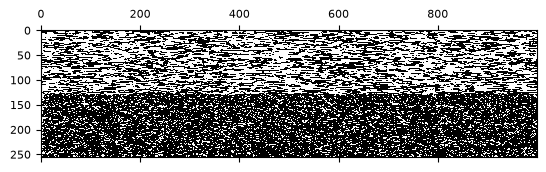

In [3]:
GRAPH = {"type": "sbm",
         "params": {"n": n, "avg_degree": avg_deg, "B": 2, "epsilon": epsilon, "delta": delta}}
A, kmax = build_graph(GRAPH, seed=11)
KERNELS = [{"type": "simple", "beta": beta1},
           {"type": "simple", "beta": beta2}]
bank = build_kernel_bank(KERNELS, kmax)
ASSIGNMENT = {"mode": "block_flip", "omega": omega}
labels = assign_kernels(n, ASSIGNMENT, 2, seed=13)
c  = np.stack([bank[labels[l]] for l in range(n)])
x0 = build_initial_state(n, rho, seed=16)
x = heterogeneous_contagion_process(A, gamma, c, x0, tmax=tmax, random_seed=17)
M, N = get_activations(np.transpose(x), A, kmax)

plt.spy(x.T)

In [4]:
fpath = "./fig1_posterior_mus.npy"
if not os.path.isfile(fpath): # skip running inference if posterior draws saved
    configf = '../config/models/nonparametric_eb.yaml'
    res = fit_stan(M, N, configf, instance_params={"stan_file": '../src/models/mixture_nonparametric_eb.stan', "K": 1})
    mus = get_posterior_draws(res, "mu")
    np.save("fig1_posterior_mus.npy", mus[:, 0, :])

mus = np.load("fig1_posterior_mus.npy")
mu = np.mean(mus, axis=0); mu.shape # should be (kmax,)

(30,)

In [5]:
# compute 
L = M + N; L
mask = np.where(L > 0)
empirical_nus = np.stack([range(1, kmax+1)] * n)[mask].flatten()
empirical_infection = M[mask].flatten() / L[mask].flatten()

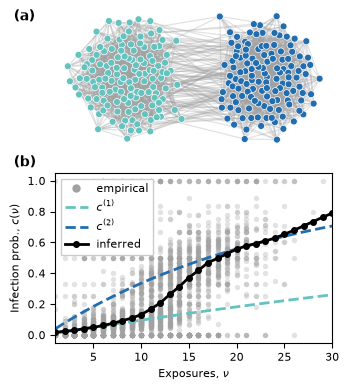

In [ ]:
fig, axs = plt.subplots(
    2,1,
    figsize=(3.375, 3.5),
    constrained_layout=True,
    gridspec_kw={"height_ratios": [1, 1.25], "hspace": 0.05},
)

# PANEL A - network visualization
ax_a = axs[0]

G = nx.from_numpy_array(A)

init_pos = {}
for i in range(n):
    x0 = -1.0 if i < n // 2 else 1.0
    init_pos[i] = (x0 + np.random.normal(0, 0.05),
                   np.random.normal(0, 0.5))
 
pos = nx.spring_layout(G, pos=init_pos, k=0.35, iterations=80, seed=11)
pos_arr = np.array([pos[i] for i in range(n)])
cx0 = pos_arr[:n//2, 0].mean()
cx1 = pos_arr[n//2:, 0].mean()
gap = 1.0
if cx1 - cx0 < gap:
    shift = (gap - (cx1 - cx0)) / 2
    for i in range(n//2):
        pos[i] = (pos[i][0] - shift, pos[i][1])
    for i in range(n//2, n):
        pos[i] = (pos[i][0] + shift, pos[i][1])

palette = [fs.palette[2], fs.palette[4]]
node_colors = [palette[labels[i]] for i in range(n)]

# draw edges
nx.draw_networkx_edges(G, pos, edgelist=[(u,v) for u, v in G.edges()], ax=ax_a,
                       width=0.9, alpha=0.30, edge_color='#a1a1a1')

# draw nodes 
nx.draw_networkx_nodes(G, pos, ax=ax_a,
                       node_color=node_colors,
                       node_size=25, linewidths=0.5,
                       edgecolors='white')

ax_a.margins(0.0)
ax_a.axis('off')
ax_a.text(-0.15, 0.9, '(a)', transform=ax_a.transAxes,
          fontweight='bold', va='bottom', ha='left')

# PANEL B - empirical infection data + kernels
ax_b = axs[1]

nus = range(1, kmax+1)
ax_b.scatter(empirical_nus, empirical_infection, color='#a1a1a1', alpha=0.3, linewidth=0.0, s=15)
ax_b.plot(nus, simple_kernel(beta1, kmax), color=fs.palette[2], linestyle='--', linewidth=2.0)
ax_b.plot(nus, simple_kernel(beta2, kmax), color=fs.palette[4], linestyle='--', linewidth=2.0)
ax_b.plot(nus, mu, color='black', linewidth=2.0, marker='o', markersize=4)

ax_b.set_xlim(1, kmax)
ax_b.set_xlabel('Exposures, $\\nu$')
ax_b.set_ylabel('Infection prob., $c(\\nu)$')

empirical_grey = mlines.Line2D([], [], label="empirical", linewidth=0.0, marker='o', markerfacecolor='#a1a1a1', markeredgewidth=0.0)
beta1_blue     = mlines.Line2D([], [], label="$c^{(1)}$", linestyle='--', color=fs.palette[2], linewidth=2.0)
beta2_blue     = mlines.Line2D([], [], label="$c^{(2)}$", linestyle='--', color=fs.palette[4], linewidth=2.0)
np_black       = mlines.Line2D([], [], label="inferred", marker='o', markersize=4, color='black', linewidth=2.0)
ax_b.legend(handles=[empirical_grey, beta1_blue, beta2_blue, np_black], handlelength=2.0, framealpha=1.0, loc='upper left', fancybox=False)
ax_b.text(-0.15, 1.02, '(b)', transform=ax_b.transAxes,
          fontweight='bold', va='bottom', ha='left')

plt.savefig('../figs/fig1.svg', bbox_inches='tight')
plt.savefig('../figs/fig1.pdf', bbox_inches='tight')

plt.show()